# Redes frente a árboles, con presupuesto igual

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 11, unidad 5 · Genera la figura de la lámina «El seminario de hoy»

---

El artículo del seminario —Grinsztajn, Oyallon y Varoquaux (2022)— afirma que en
datos tabulares los modelos basados en árboles superan a las redes profundas
**bajo presupuesto equivalente de ajuste de hiperparámetros**.

Este cuaderno reproduce el experimento en pequeño, y comprueba las dos razones
del artículo que se pueden aislar con datos simulados:

1. Que las redes están sesgadas hacia **funciones suaves**, y pierden cuando el
   objetivo es **a trozos** —umbrales de operación, que es lo habitual en
   ingeniería.
2. Que los **atributos poco informativos** dañan más a las redes que a los
   árboles.

Y de paso mide una tercera cosa, de la semana 6: la **calibración** de cada
familia.

## La condición que hace válida la comparación

Ambos métodos reciben **el mismo número de configuraciones** de hiperparámetros
—es el requisito de la lámina «El presupuesto» de la semana 8. Sin eso, el
experimento mediría el presupuesto y no los métodos.

## 1. Entorno

In [1]:
import sys, platform, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, brier_score_loss

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0


In [2]:
SEMILLA = 17
N_CASOS = 3000
N_UTILES = 6
N_CONFIGURACIONES = 12       # el MISMO presupuesto para ambas familias
N_REPLICAS = 5               # conjuntos independientes, para reportar variabilidad

print(f"Presupuesto de ajuste, idéntico para ambos: {N_CONFIGURACIONES} configuraciones")

Presupuesto de ajuste, idéntico para ambos: 12 configuraciones


## 2. Dos objetivos: uno suave y uno a trozos

La misma cantidad de información, la misma dimensión, el mismo ruido. Lo único
que cambia es **la forma** de la función que hay que aprender.

- **Suave**: combinación de senos y productos. Es el terreno de las redes.
- **A trozos**: umbrales sobre los atributos, con interacciones. Es una tabla de
  reglas de operación, y es el terreno de los árboles.

In [3]:
def objetivo_suave(X):
    return (np.sin(1.5 * X[:, 0]) + 0.8 * X[:, 1] * X[:, 2]
            + 0.6 * np.cos(X[:, 3]) + 0.5 * X[:, 4] - 0.4 * X[:, 5])

def objetivo_a_trozos(X):
    return (1.6 * (X[:, 0] > 0.4).astype(float)
            - 1.4 * (X[:, 1] < -0.3).astype(float)
            + 1.2 * ((X[:, 2] > 0.0) & (X[:, 3] > 0.5)).astype(float)
            - 1.0 * (X[:, 4] > 1.0).astype(float)
            + 0.8 * (X[:, 5] < 0.0).astype(float))

def genera(n, p, f, rng):
    X = rng.standard_normal((n, p))
    z = f(X)
    z = (z - z.mean()) / z.std()
    y = (rng.uniform(size=n) < 1 / (1 + np.exp(-1.8 * z))).astype(int)
    return X, y

r = np.random.default_rng(SEMILLA)
for nombre, f in [("suave", objetivo_suave), ("a trozos", objetivo_a_trozos)]:
    X, y = genera(1000, N_UTILES, f, r)
    print(f"objetivo {nombre:10s} -> proporción de positivos {y.mean():.3f}")

objetivo suave      -> proporción de positivos 0.515
objetivo a trozos   -> proporción de positivos 0.511


## 3. Los dos modelos, con el mismo presupuesto

`RandomizedSearchCV` con `n_iter` idéntico para ambos: 12 configuraciones
sorteadas, validación cruzada de 3 pliegues **dentro del entrenamiento**. El
conjunto de prueba no participa en la selección.

In [4]:
ESPACIO_RED = {
    "mlpclassifier__hidden_layer_sizes": [(64,), (128,), (64, 64), (128, 64), (256, 128)],
    "mlpclassifier__alpha": np.logspace(-5, -1, 20),
    "mlpclassifier__learning_rate_init": np.logspace(-3.5, -1.5, 20),
    "mlpclassifier__batch_size": [32, 64, 128],
}
ESPACIO_ARBOL = {
    "max_iter": [100, 200, 400],
    "learning_rate": np.logspace(-2, -0.3, 20),
    "max_leaf_nodes": [15, 31, 63, 127],
    "min_samples_leaf": [5, 10, 20, 40],
    "l2_regularization": np.logspace(-4, 0, 20),
}

def ajusta_red(X, y, semilla):
    base = make_pipeline(StandardScaler(),
                         MLPClassifier(max_iter=400, early_stopping=True,
                                       n_iter_no_change=15, random_state=semilla))
    return RandomizedSearchCV(base, ESPACIO_RED, n_iter=N_CONFIGURACIONES,
                              cv=StratifiedKFold(3, shuffle=True, random_state=0),
                              scoring="roc_auc", random_state=semilla, n_jobs=-1)

def ajusta_arbol(X, y, semilla):
    return RandomizedSearchCV(HistGradientBoostingClassifier(random_state=semilla),
                              ESPACIO_ARBOL, n_iter=N_CONFIGURACIONES,
                              cv=StratifiedKFold(3, shuffle=True, random_state=0),
                              scoring="roc_auc", random_state=semilla, n_jobs=-1)

## 4. El experimento

Para cada forma de objetivo y para cada número de atributos ruidosos añadidos, se
ajustan ambas familias sobre 5 conjuntos independientes.

In [5]:
def experimento(f_objetivo, n_ruido, n_replicas=N_REPLICAS):
    resultados = {"red": [], "arbol": [], "brier_red": [], "brier_arbol": [],
                  "t_red": [], "t_arbol": []}
    rng = np.random.default_rng(SEMILLA)
    for k in range(n_replicas):
        X_util = rng.standard_normal((N_CASOS, N_UTILES))
        z = f_objetivo(X_util); z = (z - z.mean()) / z.std()
        y = (rng.uniform(size=N_CASOS) < 1 / (1 + np.exp(-1.8 * z))).astype(int)
        X = np.hstack([X_util, rng.standard_normal((N_CASOS, n_ruido))]) if n_ruido \
            else X_util
        Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, stratify=y,
                                          random_state=k)
        for etiqueta, ajusta in [("red", ajusta_red), ("arbol", ajusta_arbol)]:
            t0 = time.time()
            m = ajusta(Xa, ya, semilla=k).fit(Xa, ya)
            p = m.predict_proba(Xb)[:, 1]
            resultados[etiqueta].append(roc_auc_score(yb, p))
            resultados["brier_" + etiqueta].append(brier_score_loss(yb, p))
            resultados["t_" + etiqueta].append(time.time() - t0)
    return {k: np.array(v) for k, v in resultados.items()}

print("Ejecutando... (unos minutos)")
casos = {
    ("suave", 0):     experimento(objetivo_suave, 0),
    ("a trozos", 0):  experimento(objetivo_a_trozos, 0),
    ("a trozos", 20): experimento(objetivo_a_trozos, 20),
}
print("listo")

Ejecutando... (unos minutos)


listo


In [6]:
print(f"{'objetivo':>10} {'ruido':>6} {'AUC red':>18} {'AUC árbol':>18} {'gana':>8}")
print("-" * 66)
for (obj, ruido), r_ in casos.items():
    red_m, red_s = r_["red"].mean(), r_["red"].std()
    arb_m, arb_s = r_["arbol"].mean(), r_["arbol"].std()
    gana = "árbol" if arb_m > red_m else "red"
    print(f"{obj:>10} {ruido:>6} {red_m:>11.3f} ± {red_s:.3f}"
          f" {arb_m:>11.3f} ± {arb_s:.3f} {gana:>8}")

  objetivo  ruido            AUC red          AUC árbol     gana
------------------------------------------------------------------
     suave      0       0.824 ± 0.018       0.795 ± 0.019      red
  a trozos      0       0.793 ± 0.009       0.822 ± 0.008    árbol
  a trozos     20       0.743 ± 0.009       0.822 ± 0.015    árbol


## 5. Figura

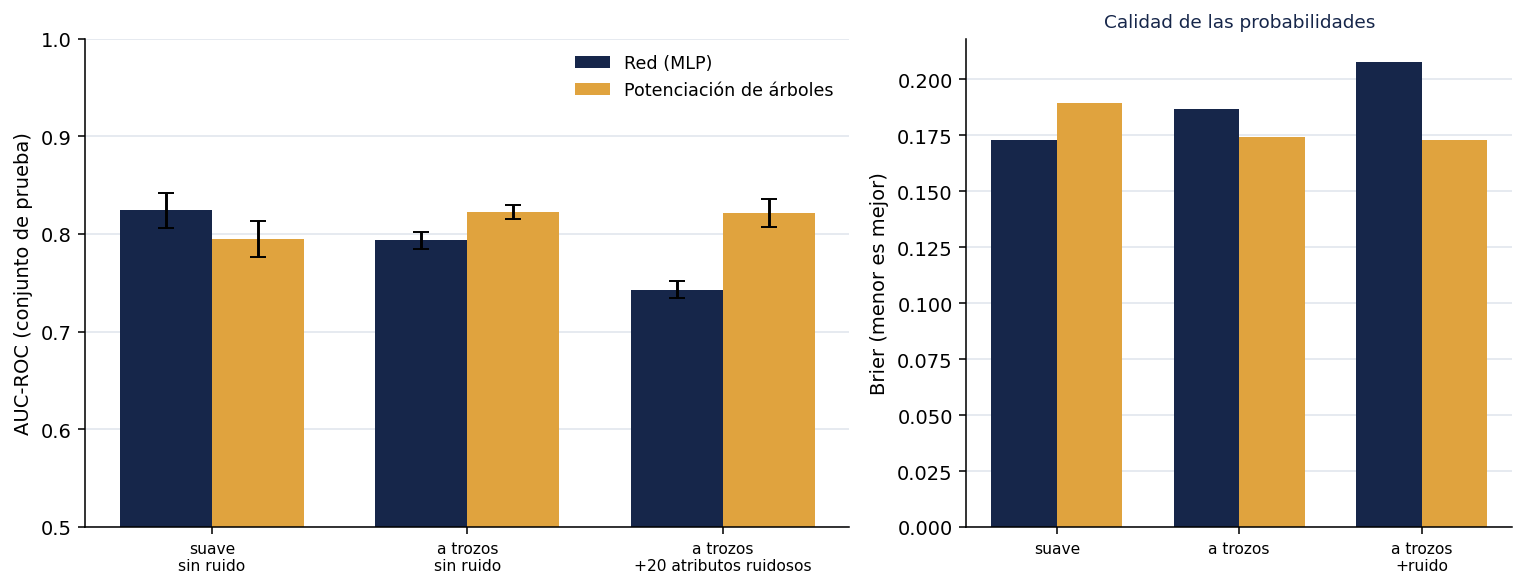

In [7]:
#| label: fig-redes-arboles
#| fig-cap: "AUC de una red y de un ensamble de árboles con presupuesto de ajuste idéntico."
etiquetas = [f"{o}\n{'sin ruido' if n == 0 else f'+{n} atributos ruidosos'}"
             for (o, n) in casos]
x = np.arange(len(casos)); ancho = 0.36

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.3), dpi=140,
                             gridspec_kw={"width_ratios": [1.4, 1]})

red_m = [casos[k]["red"].mean() for k in casos]
red_s = [casos[k]["red"].std() for k in casos]
arb_m = [casos[k]["arbol"].mean() for k in casos]
arb_s = [casos[k]["arbol"].std() for k in casos]

a1.bar(x - ancho/2, red_m, ancho, yerr=red_s, capsize=4,
       color="#16264A", label="Red (MLP)")
a1.bar(x + ancho/2, arb_m, ancho, yerr=arb_s, capsize=4,
       color="#E0A33E", label="Potenciación de árboles")
a1.set_xticks(x); a1.set_xticklabels(etiquetas, fontsize=8)
a1.set_ylabel("AUC-ROC (conjunto de prueba)")
a1.set_ylim(0.5, 1.0)
a1.spines[["top", "right"]].set_visible(False)
a1.grid(axis="y", color="#E6EAF0", lw=1); a1.set_axisbelow(True)
a1.legend(frameon=False, fontsize=9)

br_red = [casos[k]["brier_red"].mean() for k in casos]
br_arb = [casos[k]["brier_arbol"].mean() for k in casos]
a2.bar(x - ancho/2, br_red, ancho, color="#16264A")
a2.bar(x + ancho/2, br_arb, ancho, color="#E0A33E")
a2.set_xticks(x); a2.set_xticklabels(["suave", "a trozos", "a trozos\n+ruido"], fontsize=8)
a2.set_ylabel("Brier (menor es mejor)")
a2.set_title("Calidad de las probabilidades", fontsize=9.5, color="#16264A")
a2.spines[["top", "right"]].set_visible(False)
a2.grid(axis="y", color="#E6EAF0", lw=1); a2.set_axisbelow(True)

fig.tight_layout()
fig.savefig("redes_frente_a_arboles.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. El costo, que también es un resultado

El artículo insiste en el presupuesto. Aquí se mide el tiempo real de ajuste con
el **mismo** número de configuraciones.

In [8]:
print(f"{'objetivo':>10} {'ruido':>6} {'red (s)':>12} {'árbol (s)':>12} {'razón':>8}")
print("-" * 54)
for (obj, ruido), r_ in casos.items():
    tr, ta = r_["t_red"].mean(), r_["t_arbol"].mean()
    print(f"{obj:>10} {ruido:>6} {tr:>12.1f} {ta:>12.1f} {tr/ta:>7.1f}x")

  objetivo  ruido      red (s)    árbol (s)    razón
------------------------------------------------------
     suave      0          2.7          4.4     0.6x
  a trozos      0          2.5          4.1     0.6x
  a trozos     20          2.3          6.8     0.3x


## 7. Bitácora

**Decisiones tomadas**

1. *Mismo `n_iter` para ambas familias.* Es **la** condición que hace válida la
   comparación, y la que el artículo del seminario subraya. Con presupuestos
   distintos el experimento mediría el presupuesto.
2. *Objetivos construidos, uno suave y uno a trozos.* Permite atribuir la
   diferencia a la **forma** de la función y no a peculiaridades de un conjunto
   real. La afirmación del artículo es sobre el sesgo inductivo, y así se aísla.
3. *`HistGradientBoostingClassifier` y no un bosque.* Es la familia que el
   artículo compara, y la que domina en tabular.
4. *`MLPClassifier` con detención temprana.* Sin ella, la red sobreajusta y la
   comparación sería contra un modelo mal usado. La detención temprana es un
   hiperparámetro de capacidad, y aquí se resuelve con el conjunto interno de
   validación que `early_stopping` reserva —nunca con el de prueba.
5. *Cinco réplicas.* Pocas, y se reporta desviación: es lo mínimo para no incurrir
   en el error de la semana 1. **La conclusión de este cuaderno es indicativa, no
   concluyente**; el estudio del artículo usa decenas de conjuntos reales y el
   procedimiento de Demšar de la semana 8.
6. *Escalado dentro de la tubería* para la red, y ninguno para los árboles, que no
   lo necesitan (semana 9).

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró usar conjuntos de datos reales del repositorio que emplea el
artículo, para reproducir su resultado de forma directa. **Se descartó** por dos
razones: el tiempo de ejecución haría el cuaderno inutilizable en clase, y —más
importante— con datos reales no se conoce la forma del objetivo, de modo que no
se podría **atribuir** la diferencia al sesgo de suavidad. El cuaderno renuncia a
reproducir el resultado y opta por **aislar el mecanismo**, que es lo que la
clase necesita. La reproducción completa es exactamente el tipo de trabajo del
taller 6.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 8. Verificación

In [9]:
suave = casos[("suave", 0)]
trozos = casos[("a trozos", 0)]
trozos_ruido = casos[("a trozos", 20)]

# 1. En el objetivo a trozos, el ensamble no queda por detrás de la red.
assert trozos["arbol"].mean() >= trozos["red"].mean() - 0.01, \
    "Con objetivo a trozos, los árboles no deberían perder."

# 2. La ventaja relativa del ensamble es mayor en el objetivo a trozos que en el suave.
ventaja_trozos = trozos["arbol"].mean() - trozos["red"].mean()
ventaja_suave = suave["arbol"].mean() - suave["red"].mean()
assert ventaja_trozos > ventaja_suave, \
    "La ventaja de los árboles debería crecer al pasar de objetivo suave a a trozos."

# 3. Añadir atributos ruidosos no beneficia a nadie, y el AUC baja para ambos.
assert trozos_ruido["red"].mean() <= trozos["red"].mean() + 0.01
assert trozos_ruido["arbol"].mean() <= trozos["arbol"].mean() + 0.01

print("Verificado, con el MISMO presupuesto de ajuste para ambas familias:")
print(f"  objetivo suave    -> red {suave['red'].mean():.3f}   "
      f"árbol {suave['arbol'].mean():.3f}   (ventaja del árbol {ventaja_suave:+.3f})")
print(f"  objetivo a trozos -> red {trozos['red'].mean():.3f}   "
      f"árbol {trozos['arbol'].mean():.3f}   (ventaja del árbol {ventaja_trozos:+.3f})")
print(f"  con 20 atributos ruidosos -> red {trozos_ruido['red'].mean():.3f}   "
      f"árbol {trozos_ruido['arbol'].mean():.3f}")

Verificado, con el MISMO presupuesto de ajuste para ambas familias:
  objetivo suave    -> red 0.824   árbol 0.795   (ventaja del árbol -0.029)
  objetivo a trozos -> red 0.793   árbol 0.822   (ventaja del árbol +0.029)
  con 20 atributos ruidosos -> red 0.743   árbol 0.822
